In [ ]:
import os

# Select the backend before the first PyRITE import; restart to change it.
os.environ.setdefault("PYRITE_MC_BACKEND", "cpu")
import marimo as mo  # noqa: F401
import matplotlib.pyplot as plt
import numpy as np

import pyrite

_ = pyrite.fetch_tables()  # Reuse the installed tables without network access.
tables_ready = True

# Sampling, convergence and performance

[![Open in Molab](https://marimo.io/molab-shield.svg)](https://molab.marimo.io/github/Quantum-Light-Matter-Cooperative-QLMC/pyrite/blob/main/docs/notebooks/07-sampling-convergence-performance.py)

**Captured results.** Edit and recompute in Molab or local marimo; this static page does not execute PyRITE or download reference tables.

Compare PXR/CBS yields for six fixed-history budgets and one
adaptive stopping policy. All runs use a 30 keV beam, 100 nm HOPG,
135° observation, and no bremsstrahlung.

The **600–2,000 eV** band integral is less noisy than individual grid
samples. Small CPU budgets illustrate the method, not validated precision;
sampled histories are not physical bunch charge.

In [ ]:
from time import perf_counter

from pyrite import simulate
from pyrite.beams import Beam, PointBunch, PointSpot
from pyrite.config import AdaptiveSampling, CxrReflections, FixedSampling, Numerics, Physics
from pyrite.detectors import Detector
from pyrite.geometry import Footprint, Slab

beam = Beam(energy_keV=30.0, transverse=PointSpot(), longitudinal=PointBunch())
target = Slab("hopg", thickness_ang=1_000.0, tilt_deg=30.0, footprint=Footprint(5, 5))
detector = Detector(observation_angle_deg=135.0)
physics = Physics(brem_source="none")
reflections = CxrReflections(n_families=2)
band_eV = (600.0, 2_000.0)
budgets = (256, 1_024, 4_096, 8_192, 16_384, 32_768)
electron_block_size = 256  # Adaptive stopping checks after each transport block.
spectrum_chunk_size = 512  # Segments per spectrum reduction, not electron histories.

In [ ]:
assert tables_ready  # Wait for reference tables before executing transport.
# Both policies use the same per-electron CPU transport core and CXR chunk.
# One untimed warmup reduces, but does not eliminate, first-call compilation costs.
_ = simulate(
    beam,
    target,
    detector,
    physics=physics,
    numerics=Numerics(
        sampling=FixedSampling(cxr_electrons=16, brem_electrons=16),
        cxr_reflections=reflections,
        cxr_chunk=spectrum_chunk_size,
        transport_core="per-electron",
    ),
)
fixed_rows = []
for _n in budgets:
    _start = perf_counter()
    _result = simulate(
        beam,
        target,
        detector,
        physics=physics,
        numerics=Numerics(
            sampling=FixedSampling(cxr_electrons=_n, brem_electrons=_n),
            cxr_reflections=reflections,
            cxr_chunk=spectrum_chunk_size,
            transport_core="per-electron",
        ),
    )
    _elapsed = perf_counter() - _start
    _spectrum = _result.cxr.incoherent
    _grid = _spectrum.photon_energy_eV
    _lo, _hi = band_eV
    assert _grid[0] <= _lo < _hi <= _grid[-1]
    _nodes = np.r_[_lo, _grid[(_grid > _lo) & (_grid < _hi)], _hi]
    _yield = float(np.trapezoid(np.interp(_nodes, _grid, _spectrum.density), _nodes))
    assert np.isfinite(_yield) and _yield >= 0.0
    fixed_rows.append(
        {
            "histories": int(_result.case["Ne"]),
            "seed": int(_result.case["seed"]),
            "yield_per_electron_sr": _yield,
            "elapsed_s": _elapsed,
            "source_identity": _result.provenance["identity_digest"],
        }
    )
assert [row["histories"] for row in fixed_rows] == list(budgets)

## Adaptive stopping

`AdaptiveSampling` monitors the **per-electron** relative standard error
(RSE) of the selected CXR band contribution, with additional maximum-share,
effective-sample-size and stability guards. This is **not** an RSE estimate
for each photon-energy bin. A run can reach its maximum without convergence.

`block_electrons` determines how often stopping is checked; `cxr_chunk`
separately controls the spectrum-reduction kernel. The loose RSE target
is illustrative, and the default safeguards remain enabled.

In [ ]:
assert tables_ready  # Wait for reference tables before executing transport.

policy = AdaptiveSampling(
    target_rse=0.1,
    max_electrons=32_768,
    block_electrons=electron_block_size,
    observables=("cxr",),
    band_eV=band_eV,
)
_start = perf_counter()
adaptive_result = simulate(
    beam,
    target,
    detector,
    physics=physics,
    numerics=Numerics(
        sampling=policy,
        cxr_reflections=reflections,
        cxr_chunk=spectrum_chunk_size,
        transport_core="per-electron",
    ),
)
_elapsed = perf_counter() - _start
_spectrum = adaptive_result.cxr.incoherent
_grid = _spectrum.photon_energy_eV
_lo, _hi = band_eV
assert _grid[0] <= _lo < _hi <= _grid[-1]
_nodes = np.r_[_lo, _grid[(_grid > _lo) & (_grid < _hi)], _hi]
_yield = float(np.trapezoid(np.interp(_nodes, _grid, _spectrum.density), _nodes))
assert np.isfinite(_yield) and _yield >= 0.0
_stop = adaptive_result.provenance["adaptive_sampling"]
_cxr_status = _stop["statistics"]["cxr"]
adaptive_row = {
    "histories": int(_stop["realized_electrons"]),
    "stop_reason": _stop["stop_reason"],
    "statistics_limited": _stop["statistics_limited"],
    "rse": _cxr_status["relative_se"],
    "effective_sample_size": _cxr_status["effective_sample_size"],
    "max_electron_share": _cxr_status["max_electron_share"],
    "stability": _cxr_status["stability"],
    "guard_passes": _cxr_status["passes"],
    "seed": int(adaptive_result.case["seed"]),
    "yield_per_electron_sr": _yield,
    "elapsed_s": _elapsed,
    "target_rse": policy.target_rse,
    "max_electrons": policy.max_electrons,
    "source_identity": adaptive_result.provenance["identity_digest"],
}
stopping_diagnostics = _stop

In [ ]:
mo.json(
    {
        "fixed_budget": fixed_rows,
        "adaptive": adaptive_row,
        "adaptive_stopping_diagnostics": stopping_diagnostics,
        "note": "Elapsed times are environment-specific, not portable GPU/CPU benchmarks.",
    }
)

<marimo-json-output data-json-data='{"fixed_budget":[{"histories":256,"seed":1,"yield_per_electron_sr":1.1370006696615955e-7,"elapsed_s":0.13986009400014154,"source_identity":"cd9b16b2b7eb81a83a5ad7903a9298f2efc157a8e19da603d8fe3d1a55a702a5"},{"histories":1024,"seed":1,"yield_per_electron_sr":1.1337416570393222e-7,"elapsed_s":0.48149925699999585,"source_identity":"62aaf0de46c0e754eed1d0f4dcd27a5223e5cd83796b66250bb133f026ee6c8c"},{"histories":4096,"seed":1,"yield_per_electron_sr":1.133832547310012e-7,"elapsed_s":2.0781304619995353,"source_identity":"75cfeb48cecc335741aead81c079e643a56c6e1a27f32a26c2e63da315dcd397"},{"histories":8192,"seed":1,"yield_per_electron_sr":1.1332684472435915e-7,"elapsed_s":3.676584640999863,"source_identity":"55fe48ba83daeecd1b3b06aa7579f41352db6e254e5977f8618b439ab90e5ebe"},{"histories":16384,"seed":1,"yield_per_electron_sr":1.1330287287189257e-7,"elapsed_s":10.23912920299972,"source_identity":"b0bb8c23d397a17ce73973149e704be61caa7a1009c58def40798c12e812b50e"},{"histories":32768,"seed":1,"yield_per_electron_sr":1.1333229667088497e-7,"elapsed_s":14.799190024999916,"source_identity":"da8f5a3b7e7f86dac123b26d092de4fc2726273548202333e62a412b986939df"}],"adaptive":{"histories":1024,"stop_reason":"converged","statistics_limited":false,"rse":0.002501345509210702,"effective_sample_size":1017.4874351937768,"max_electron_share":0.0027392020511017748,"stability":0.004337179412025244,"guard_passes":{"relative_se":true,"max_electron_share":true,"effective_sample_size":true,"stability":true},"seed":1,"yield_per_electron_sr":1.1337416570393222e-7,"elapsed_s":0.5570522130001336,"target_rse":0.1,"max_electrons":32768,"source_identity":"9d92cbae3ca0a984911b34cab70e901759fd28f80edbf2acef010be7dc607001"},"adaptive_stopping_diagnostics":{"mode":"adaptive","precision":{"target_rse":0.1,"min_electrons":256,"max_electrons":32768,"block_electrons":256,"observables":["line"],"max_electron_share":0.05,"min_effective_electrons":100.0,"stability_blocks":3,"stability_fraction":0.5,"pilot_electrons":null,"band_eV":[600.0,2000.0],"batch_means_band_eV":null},"target_rse":0.1,"min_electrons":256,"max_electrons":32768,"block_electrons":256,"observables":["cxr"],"guards":{"max_electron_share":0.05,"min_effective_electrons":100.0,"stability_blocks":3,"stability_fraction":0.5},"band_eV":[600.0,2000.0],"realized_electrons":1024,"realized_electrons_brem":1024,"stop_reason":"converged","statistics_limited":false,"checks":4,"pilot":null,"replayed_transport":false,"statistics":{"cxr":{"n_electrons":1024,"mean":1.1452375404253678e-7,"relative_se":0.002501345509210702,"max_electron_share":0.0027392020511017748,"effective_sample_size":1017.4874351937768,"stability":0.004337179412025244,"passes":{"relative_se":true,"max_electron_share":true,"effective_sample_size":true,"stability":true},"converged":true}},"transport_core":"per-electron"},"note":"Elapsed times are environment-specific, not portable GPU/CPU benchmarks."}' data-value-types='"json"'>

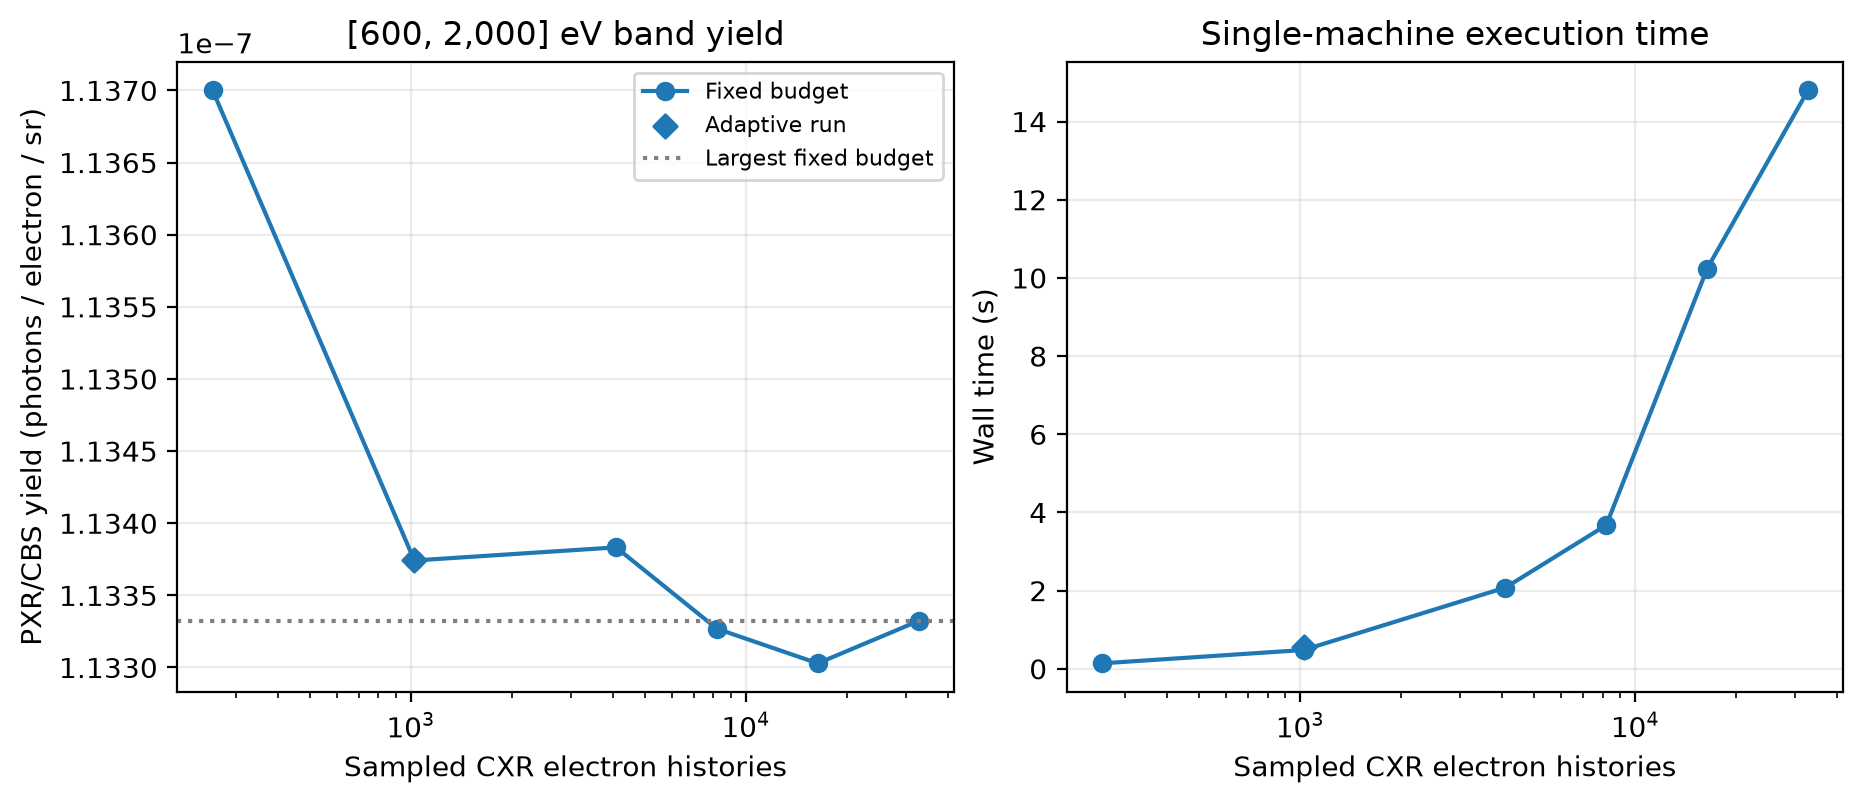

In [ ]:
_counts = np.array(budgets, dtype=float)
_yields = np.array([row["yield_per_electron_sr"] for row in fixed_rows])
_times = np.array([row["elapsed_s"] for row in fixed_rows])
fig_convergence, (_yield_ax, _time_ax) = plt.subplots(
    1, 2, figsize=(9.2, 3.9), layout="constrained"
)
_yield_ax.plot(_counts, _yields, "o-", label="Fixed budget")
_yield_ax.scatter(
    [adaptive_row["histories"]],
    [adaptive_row["yield_per_electron_sr"]],
    marker="D",
    label="Adaptive run",
    zorder=3,
)
_yield_ax.axhline(_yields[-1], color="grey", ls=":", label="Largest fixed budget")
_yield_ax.set(
    xlabel="Sampled CXR electron histories",
    ylabel="PXR/CBS yield (photons / electron / sr)",
    title="[600, 2,000] eV band yield",
    xscale="log",
)
_yield_ax.legend(fontsize=8)
_yield_ax.grid(alpha=0.25)

_time_ax.plot(_counts, _times, "o-", label="Fixed budget")
_time_ax.scatter(
    [adaptive_row["histories"]],
    [adaptive_row["elapsed_s"]],
    marker="D",
    label="Adaptive run",
    zorder=3,
)
_time_ax.set(
    xlabel="Sampled CXR electron histories",
    ylabel="Wall time (s)",
    title="Single-machine execution time",
    xscale="log",
)
_time_ax.grid(alpha=0.25)
fig_convergence  # noqa: B018 - captured by marimo

## Interpretation

The largest fixed-budget yield is only a reference, **not ground truth**.
Both modes use the default seed 1, the same per-electron CPU core, the same CXR
spectrum chunk size, and equal CXR/bremsstrahlung transport populations.
Those choices matter even with bremsstrahlung scoring disabled: the second
population affects transport energy cutoffs. Fixed-budget points share
random draws, so their spread is **not** an independent-sample uncertainty.

Check `stop_reason`, `statistics_limited`, the measured RSE, and every
entry in `guard_passes` before calling an adaptive run converged. The
requested `case["Ne"]` remains its *maximum*, for provenance and cache
identity; the plotted count is `realized_electrons`. The stopping monitor
measures per-electron CXR mass, whereas the plot integrates the final
gridded spectral density. Changing reflection families or photon grids
tests systematic discretization, not sampling convergence.

Wall times depend on compilation, caching and hardware. The untimed
warmup helps, but these are **not portable benchmarks**. These runs do
not estimate uncertainty across independent seeds. Use `transport_core="cuda"` consistently for
GPU comparisons. Try increasing
the budgets and compare the [sampling reference](https://pyrite.readthedocs.io/en/latest/reference/python-api/config.html)
and [performance guidance](https://pyrite.readthedocs.io/en/latest/computation/index.html).

## Continue learning

Next: [Parameter sweeps](08-parameter-sweeps.ipynb).
See [precision and tolerances](../../computation/precision-and-tolerances.md)
for stopping controls and the [configuration API](../../reference/python-api/config.md)
for their Python interfaces. [Statistical methods](../../computation/statistical-methods.md)
explain uncertainty; [adaptive-stopping evidence](../../validation/beam-transport/adaptive-sample-size-stopping.md)
records the estimator's assumptions and checks.

{download}`Download canonical Marimo notebook <../07-sampling-convergence-performance.py>`